#Загрузка и подготовка данных

**Загрузка библиотек**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Загружаем библиотеки для работы с финансовыми данными с Yahoo Finance
import yfinance as yf

In [ ]:
# Библиотеки для машинного обучения и предобработки данных
from sklearn.preprocessing import MinMaxScaler # для нормализации данных (масштабирование)
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error # метрики оценки моделей

In [ ]:
# Библиотеки для глубокого обучения
import tensorflow as tf
from tensorflow.keras.models import Sequential # Последовательная модель нейронной сети
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout # Слои нейронных сетей

In [ ]:
import warnings
warnings.filterwarnings('ignore') # Отключаем предупреждения для чистоты вывода

Используем данные по акциям BTC. Данные содержат историческую информацию о торгах этими акциями на бирже.

В наборе данных представлены:
- Цена открытия (Open): Цена, по которой начались торги в этот день.
- Максимальная цена (High): Самая высокая цена за торговый день.
- Минимальная цена (Low): Самая низкая цена за торговый день.
- Цена закрытия (Close): Цена, по которой закрылись торги.
- Объем торгов (Volume): Количество торгуемых акций.

In [ ]:
# Загрузка данных о котировках акций
ticker = 'BTC-USD'  # Указываем тикер акции (в данном случае Bitcoin USD Price)
data = yf.download(ticker, start='2020-01-01', end='2023-10-01')  # Загружаем данные с Yahoo Finance
data = data[['Close']]  # Оставляем только столбец с ценами закрытия


[*********************100%***********************]  1 of 1 completed


In [ ]:
# Загрузка данных акций Bitcoin USD Price
ticker = "BTC-USD"  # Указываем тикер акции Bitcoin USD Price.
data = yf.download(ticker, start='2020-01-01', end='2023-10-01') # Загружаем данные с Yahoo Finance
print(f"Загружено данных: {data.shape[0]} торговых дней")
print(f"Период: c {data.index[0].date()} по {data.index[-1].date()}")
print(f"Диапазон цены BTC-USD: от ${data['Close'].min().item():.2f} до ${data['Close'].max().item():.2f}")

[*********************100%***********************]  1 of 1 completed

Загружено данных: 1369 торговых дней
Период: c 2020-01-01 по 2023-09-30
Диапазон цены BTC-USD: от $4970.79 до $67566.83


In [ ]:
data

Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,
2020-01-01,7200.174316,7254.330566,7174.944336,7194.892090,18565664997
2020-01-02,6985.470215,7212.155273,6935.270020,7202.551270,20802083465
2020-01-03,7344.884277,7413.715332,6914.996094,6984.428711,28111481032
2020-01-04,7410.656738,7427.385742,7309.514160,7345.375488,18444271275
2020-01-05,7411.317383,7544.497070,7400.535645,7410.451660,19725074095
...,...,...,...,...,...
2023-09-26,26217.250000,26389.884766,26090.712891,26294.757812,9985498161
2023-09-27,26352.716797,26817.841797,26111.464844,26209.498047,11718380997


**Визуализация данных**

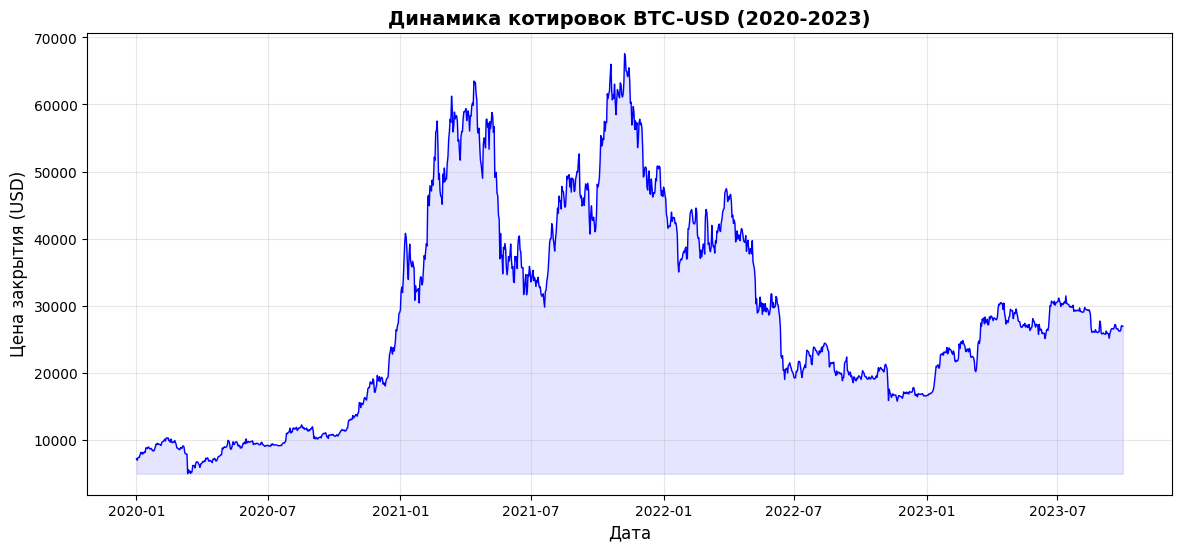

In [ ]:
plt.figure(figsize=(14, 6))
close_prices = data['Close'].values.flatten()
plt.plot(data.index, close_prices, color='blue', linewidth=1)
plt.title('Динамика котировок BTC-USD (2020-2023)', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Цена закрытия (USD)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.fill_between(data.index, close_prices.min(), close_prices, alpha=0.1, color='blue')
plt.show()

**Предобработка данных**

In [ ]:
# Используем только цену закрытия для прогнозирования
prices = data['Close'].values.reshape(-1, 1)

In [ ]:
# Нормализация данных (приведение к диапазону 0-1)
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_prices = scaler.fit_transform(prices)

In [ ]:
# Функция для создания оконных данных
def create_dataset(data, time_steps=50):
    X, y = [], []
    for i in range(len(data) - time_steps - 1):
        X.append(data[i:(i + time_steps), 0])
        y.append(data[i + time_steps, 0])
    return np.array(X), np.array(y)

In [ ]:
# Создаем датасет с окном 50 дней (примерно 3 торговых месяца)
time_steps = 50

X, y = create_dataset(scaled_prices, time_steps)

# Преобразуем в 3D массив для RNN (samples, time_steps, features)
X = X.reshape(X.shape[0], X.shape[1], 1)

# Разделение на обучающую и тестовую выборки
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")
print(f"Общее количество последовательностей: {len(X)}")

Размер обучающей выборки: (1054, 50, 1)
Размер тестовой выборки: (264, 50, 1)
Общее количество последовательностей: 1318


**RNN (Recurrent Neural Network) - рекуррентная нейронная сеть**

In [ ]:
# Создание модели RNN
def build_rnn_model():
    model = Sequential([
        SimpleRNN(40, return_sequences=True, input_shape=(time_steps, 1)),
        Dropout(0.2),
        SimpleRNN(50),
        Dropout(0.2),
        Dense(20, activation='relu'),
        Dense(1)
    ])
    return model

# Компиляция и обучение RNN
rnn_model = build_rnn_model()
rnn_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

print("Обучение RNN модели...")
rnn_history = rnn_model.fit(
    X_train, y_train,
    epochs=35,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Обучение RNN модели...
Epoch 1/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 0.0583 - mae: 0.1772 - val_loss: 0.0045 - val_mae: 0.0600
Epoch 2/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0196 - mae: 0.1017 - val_loss: 0.0013 - val_mae: 0.0283
Epoch 3/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0134 - mae: 0.0843 - val_loss: 7.4514e-04 - val_mae: 0.0203
Epoch 4/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0114 - mae: 0.0795 - val_loss: 0.0017 - val_mae: 0.0366
Epoch 5/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0089 - mae: 0.0690 - val_loss: 0.0011 - val_mae: 0.0295
Epoch 6/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0084 - mae: 0.0670 - val_loss: 8.7294e-04 - val_mae: 0.0257
Epoch 7/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0072 - mae: 0.0615 - val_loss: 3.5647e-04 - val_mae: 0.0137
Epoch 8/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0070 - mae: 0.0605 - val_loss: 3.8638e-04 - val_mae: 0.0151
Epoch 9/35
30/30 ━━━━━━━━

**LSTM (Long Short-Term Memory) - долгая краткосрочная память**

In [ ]:
# Создание модели LSTM с двумя слоями
def build_lstm_model():
    model = Sequential([
        LSTM(40, return_sequences=True, input_shape=(time_steps, 1)),
        Dropout(0.2),
        LSTM(40, return_sequences=True),
        Dropout(0.2),
        LSTM(40),
        Dropout(0.2),
        Dense(20, activation='relu'),
        Dense(1)
    ])
    return model

# Компиляция и обучение LSTM
lstm_model = build_lstm_model()
lstm_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

print("Обучение LSTM модели...")
lstm_history = lstm_model.fit(
    X_train, y_train,
    epochs=35,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Обучение LSTM модели...
Epoch 1/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 76ms/step - loss: 0.0503 - mae: 0.1600 - val_loss: 0.0078 - val_mae: 0.0863
Epoch 2/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0083 - mae: 0.0644 - val_loss: 3.4382e-04 - val_mae: 0.0143
Epoch 3/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - loss: 0.0076 - mae: 0.0610 - val_loss: 0.0012 - val_mae: 0.0294
Epoch 4/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0073 - mae: 0.0598 - val_loss: 4.2377e-04 - val_mae: 0.0142
Epoch 5/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - loss: 0.0061 - mae: 0.0547 - val_loss: 7.9602e-04 - val_mae: 0.0224
Epoch 6/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 0.0063 - mae: 0.0549 - val_loss: 3.4619e-04 - val_mae: 0.0151
Epoch 7/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 0.0059 - mae: 0.0540 - val_loss: 3.4641e-04 - val_mae: 0.0153
Epoch 8/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0056 - mae: 0.0527 - val_loss: 4.3662e-04 - val_mae: 0.0145
Epoch 9/35
30/30

**GRU (Gated Recurrent Unit) - рекуррентный блок с управляемыми воротами**

In [ ]:
# Создание модели GRU
def build_gru_model():
    model = Sequential([
        GRU(40, return_sequences=True, input_shape=(time_steps, 1)),
        Dropout(0.2),
        GRU(40),
        Dropout(0.2),
        Dense(20, activation='relu'),
        Dense(1)
    ])
    return model

# Компиляция и обучение GRU
gru_model = build_gru_model()
gru_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

print("Обучение GRU модели...")
gru_history = gru_model.fit(
    X_train, y_train,
    epochs=35,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Обучение GRU модели...
Epoch 1/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - loss: 0.0872 - mae: 0.2170 - val_loss: 0.0032 - val_mae: 0.0550
Epoch 2/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0106 - mae: 0.0757 - val_loss: 2.5524e-04 - val_mae: 0.0138
Epoch 3/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - loss: 0.0059 - mae: 0.0527 - val_loss: 1.7570e-04 - val_mae: 0.0103
Epoch 4/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - loss: 0.0049 - mae: 0.0485 - val_loss: 1.3093e-04 - val_mae: 0.0070
Epoch 5/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0044 - mae: 0.0450 - val_loss: 1.7848e-04 - val_mae: 0.0107
Epoch 6/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0041 - mae: 0.0439 - val_loss: 2.2602e-04 - val_mae: 0.0130
Epoch 7/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0039 - mae: 0.0433 - val_loss: 1.5166e-04 - val_mae: 0.0080
Epoch 8/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - loss: 0.0032 - mae: 0.0381 - val_loss: 1.8874e-04 - val_mae: 0.0097
Epoch 9/35
30

#Сравнительный анализ обучения моделей

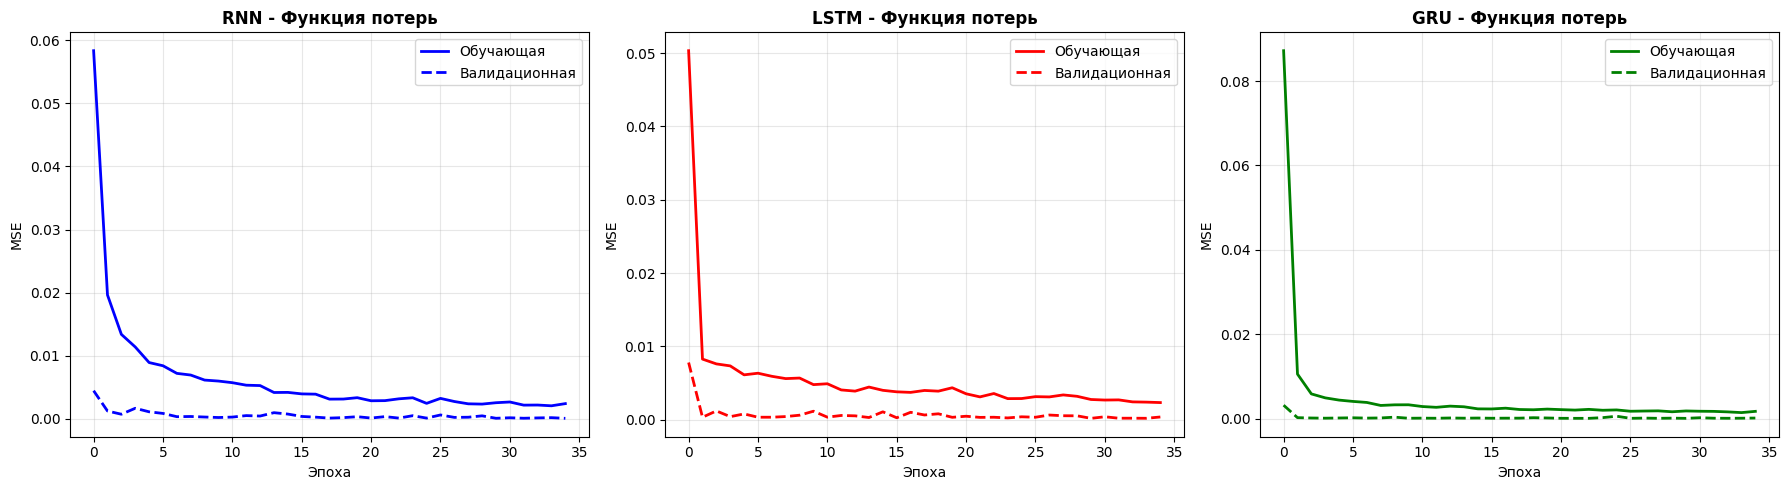

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

histories = [rnn_history, lstm_history, gru_history]
model_names = ['RNN', 'LSTM', 'GRU']
colors = ['blue', 'red', 'green']

for idx, (history, name, color) in enumerate(zip(histories, model_names, colors)):
    axes[idx].plot(history.history['loss'], color=color, linewidth=2, label='Обучающая')
    axes[idx].plot(history.history['val_loss'], color=color, linewidth=2, linestyle='--', label='Валидационная')
    axes[idx].set_title(f'{name} - Функция потерь', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Эпоха')
    axes[idx].set_ylabel('MSE')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

На графиках показано изменение функции потерь (MSE) в процессе обучения. Сплошные линии — потери на обучающей выборке, пунктирные — на валидационной. Хорошим признаком является снижение обеих кривых и малый разрыв между ними.  GRU сходятся быстрее и стабильнее.

#Прогнозирование и оценка точности

**Прогнозирование на тестовой выборке**

In [ ]:
# Прогнозирование всеми моделями
rnn_predictions = rnn_model.predict(X_test)
lstm_predictions = lstm_model.predict(X_test)
gru_predictions = gru_model.predict(X_test)

# Обратное преобразование масштабирования
rnn_predictions = scaler.inverse_transform(rnn_predictions)
lstm_predictions = scaler.inverse_transform(lstm_predictions)
gru_predictions = scaler.inverse_transform(gru_predictions)

# Фактические значения (обратное преобразование)
y_test_original = scaler.inverse_transform(y_test.reshape(-1, 1))

# Расчет метрик
def calculate_metrics(actual, predicted, model_name):
    mae = mean_absolute_error(actual, predicted)
    mape = mean_absolute_percentage_error(actual, predicted) * 100

    return {
        'Модель': model_name,
        'MAE': round(mae, 2),
        'MAPE (%)': round(mape, 2)
    }

# Сбор метрик для всех моделей
metrics = []
for pred, name in zip([rnn_predictions, lstm_predictions, gru_predictions], ['RNN', 'LSTM', 'GRU']):
    metrics.append(calculate_metrics(y_test_original, pred, name))

# Создание таблицы метрик
metrics_df = pd.DataFrame(metrics)
print(metrics_df.to_string(index=False))

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step
Модель     MAE  MAPE (%)
   RNN  787.23      2.95
  LSTM 1096.37      4.21
   GRU  519.21      2.02


MAE - средняя абсолютная ошибка. Показывает на сколько пунктов в среднем ошибается модель.

MAPE - средняя абсолютная процентная ошибка. Показывает на сколько процентов в среднем ошибается модель.

**Визуализация прогнозов**

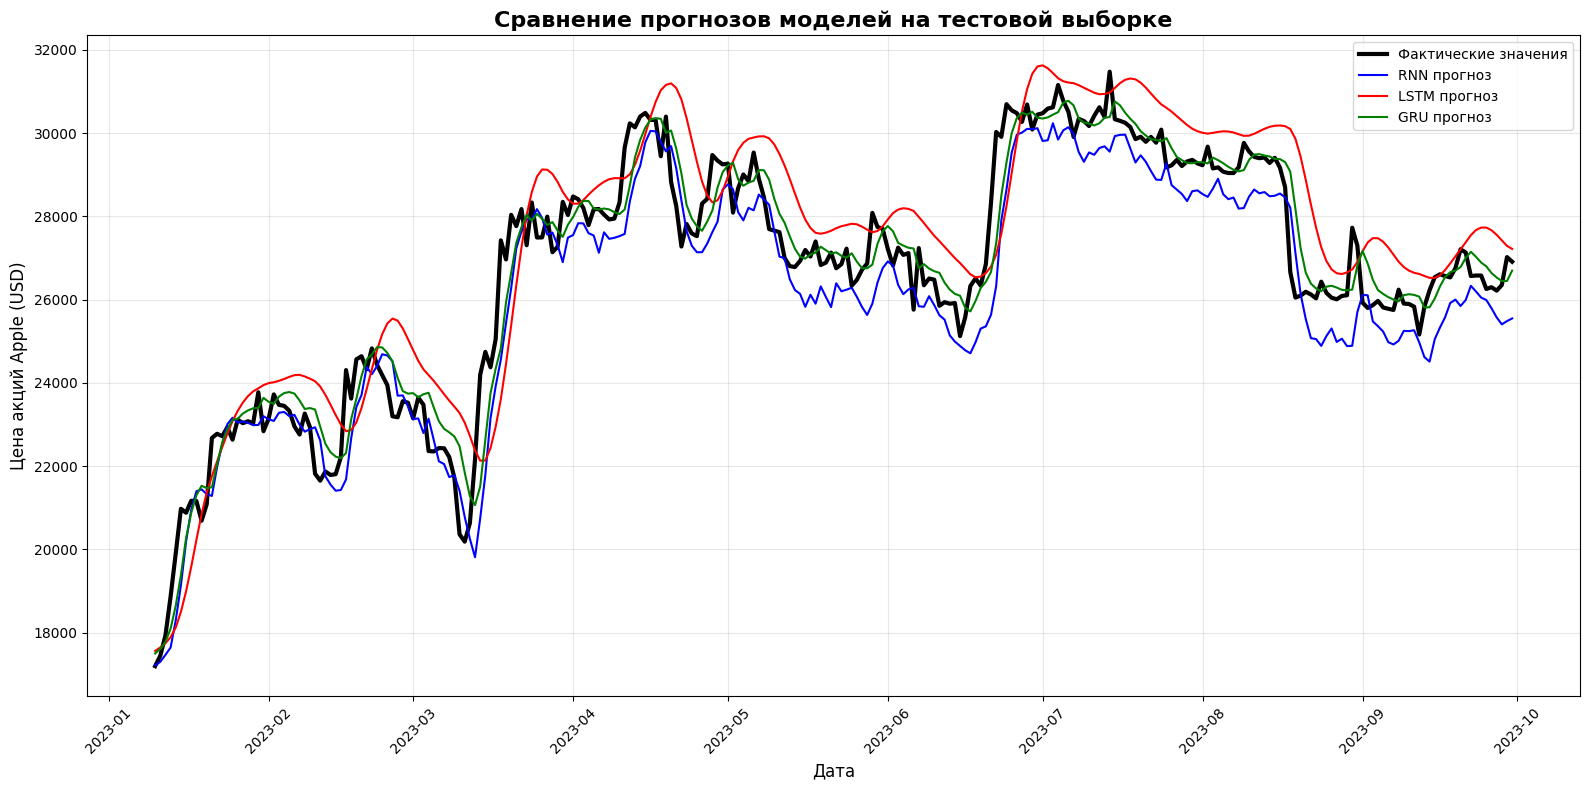

In [ ]:
# Визуализация прогнозов
plt.figure(figsize=(16, 8))

# Определяем даты для тестовой выборки
test_dates = data.index[train_size + time_steps + 1: train_size + time_steps + 1 + len(y_test_original)]

# Фактические значения
plt.plot(test_dates, y_test_original, color='black', linewidth=3, label='Фактические значения')

# Прогнозы моделей
plt.plot(test_dates, rnn_predictions, color='blue', linewidth=1.5, label='RNN прогноз')
plt.plot(test_dates, lstm_predictions, color='red', linewidth=1.5, label='LSTM прогноз')
plt.plot(test_dates, gru_predictions, color='green', linewidth=1.5, label='GRU прогноз')

plt.title('Сравнение прогнозов моделей на тестовой выборке', fontsize=16, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Цена акций Apple (USD)', fontsize=12)
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

На графике показаны фактические значения цены акций Apple (черная линия) и прогнозы трех моделей. Чем ближе линии прогнозов к фактической линии, тем точнее модель. LSTM и GRU лучше следуют трендам и точнее предсказывают развороты.

#Использование данных для планирования

**Прогнозирование на несколько дней вперед с использованием обученной модели**

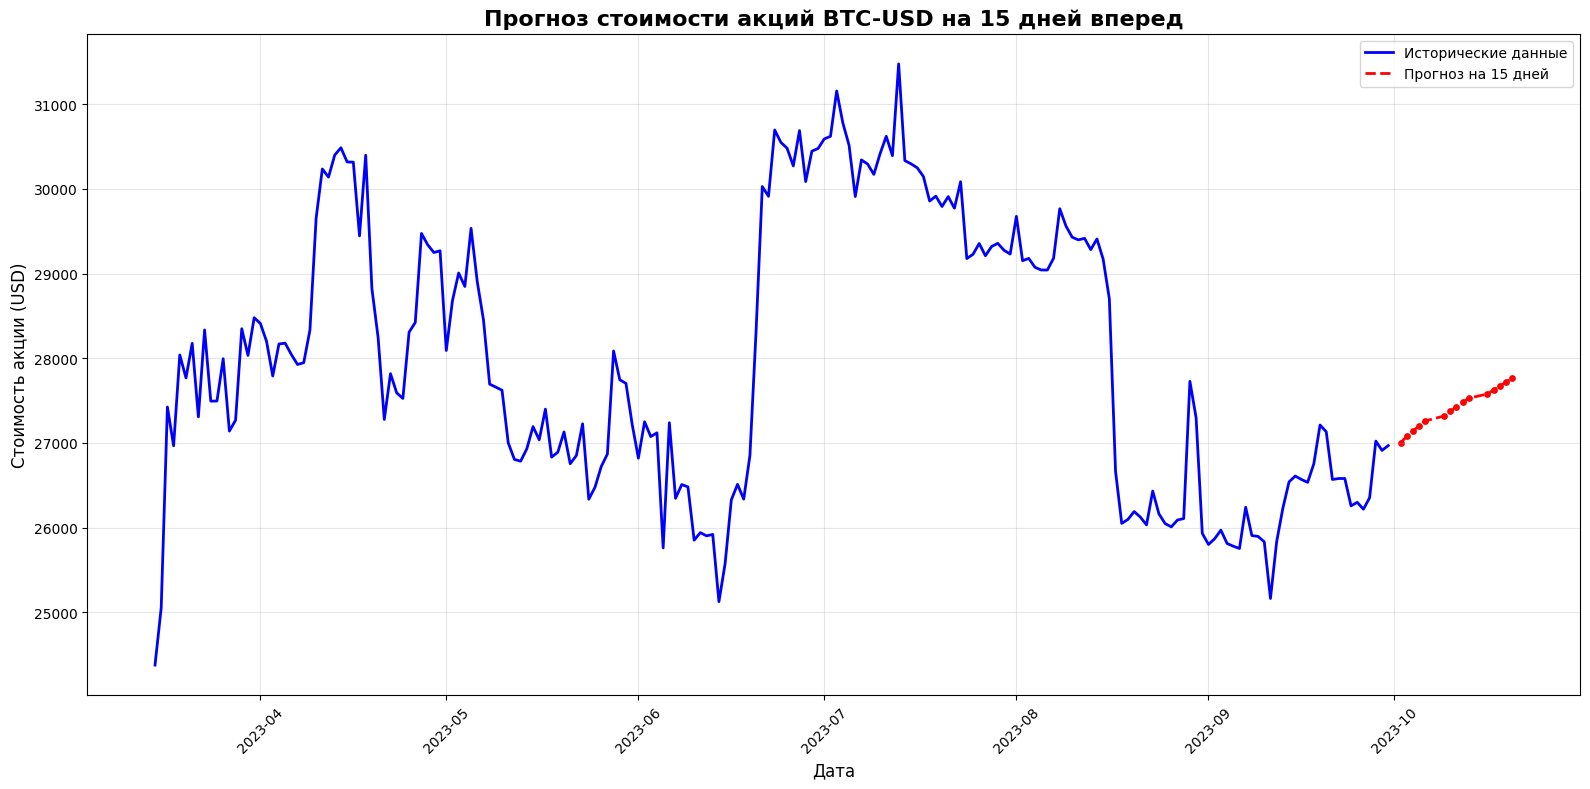

Текущее значение BTC-USD: 26967.92
Прогноз через 15 дней: 27761.95
Ожидаемое изменение: 2.94%


In [ ]:
# Прогнозирование на 30 дней вперед
def forecast_future(model, last_sequence, days_ahead=15):
    predictions = []
    current_sequence = last_sequence.copy()

    for _ in range(days_ahead):
        # Предсказание следующего значения
        pred = model.predict(current_sequence.reshape(1, time_steps, 1), verbose=0)
        predictions.append(pred[0, 0])

        # Обновление последовательности
        current_sequence = np.roll(current_sequence, -1)
        current_sequence[-1] = pred

    return np.array(predictions)
# Берем последнюю последовательность из данных
last_sequence = scaled_prices[-time_steps:]
# Прогнозируем на 30 дней вперед лучшей моделью (GRU)
future_predictions = forecast_future(gru_model, last_sequence, 15)
future_predictions = scaler.inverse_transform(future_predictions.reshape(-1, 1))
# Создаем даты для будущего прогноза
last_date = data.index[-1]
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=15, freq='B')


# Визуализация исторических данных и прогноза
plt.figure(figsize=(16, 8))

# Исторические данные (последние 200 дней)
history_days = 200
plt.plot(data.index[-history_days:], data['Close'].values[-history_days:],
         color='blue', linewidth=2, label='Исторические данные')
# Прогноз на будущее
plt.plot(future_dates, future_predictions, color='red', linewidth=2, label='Прогноз на 15 дней', linestyle='--')
plt.scatter(future_dates, future_predictions, color='red', s=15)
plt.title('Прогноз стоимости акций BTC-USD на 15 дней вперед', fontsize=16, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Стоимость акции (USD)', fontsize=12)
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# Анализ прогноза
print(f"Текущее значение BTC-USD: {data['Close'].iloc[-1].item():.2f}")
print(f"Прогноз через 15 дней: {future_predictions[-1][0]:.2f}")
print(f"Ожидаемое изменение: {((future_predictions[-1][0] / data['Close'].iloc[-1].item()) - 1) * 100:.2f}%")

Синяя линия показывает данные за последние полгода, красная пунктирная — прогноз на 30 дней вперед.

Такой прогноз можно использовать для стратегического планирования инвестиций в акции. Если прогноз показывает рост, это может быть сигналом к покупке, если падение — к продаже или ожиданию.